# Card Application Analysis

How do recorded expenditure values differ by card acceptance?

Data: [AER/CreditCard](https://vincentarelbundock.github.io/Rdatasets/doc/AER/CreditCard.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Expenditure zeros and acceptance selection require source interpretation; this is not a validated lending model.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Card Application Analysis',
 'executed_utc': '2026-11-21T10:14:15.209560+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/AER/CreditCard.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/AER/CreditCard.html',
 'sha256': '3eb5396fd275b2383536a3f1de39b22b9047a93d5c8cb0557bb1b90b1b13e0a9',
 'raw_rows': 1319,
 'analysis_rows': 1319,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,1319
1,card,object,0,0.0,2
2,reports,int64,0,0.0,13
3,age,float64,0,0.0,418
4,income,float64,0,0.0,431
5,share,float64,0,0.0,1162
6,expenditure,float64,0,0.0,981
7,owner,object,0,0.0,2
8,selfemp,object,0,0.0,2
9,dependents,int64,0,0.0,7


## SQL and analysis
Complete-case descriptive comparison of expenditure by card; show group counts, mean, minimum and maximum.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "card" AS segment, COUNT(*) AS rows_used, AVG("expenditure") AS metric, MIN("expenditure") AS minimum, MAX("expenditure") AS maximum FROM observations GROUP BY "card" ORDER BY "card";

The largest observed mean expenditure is 238.602 for yes. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,no,296,0.000000,0.0,0.000
1,yes,1023,238.602421,0.0,3099.505


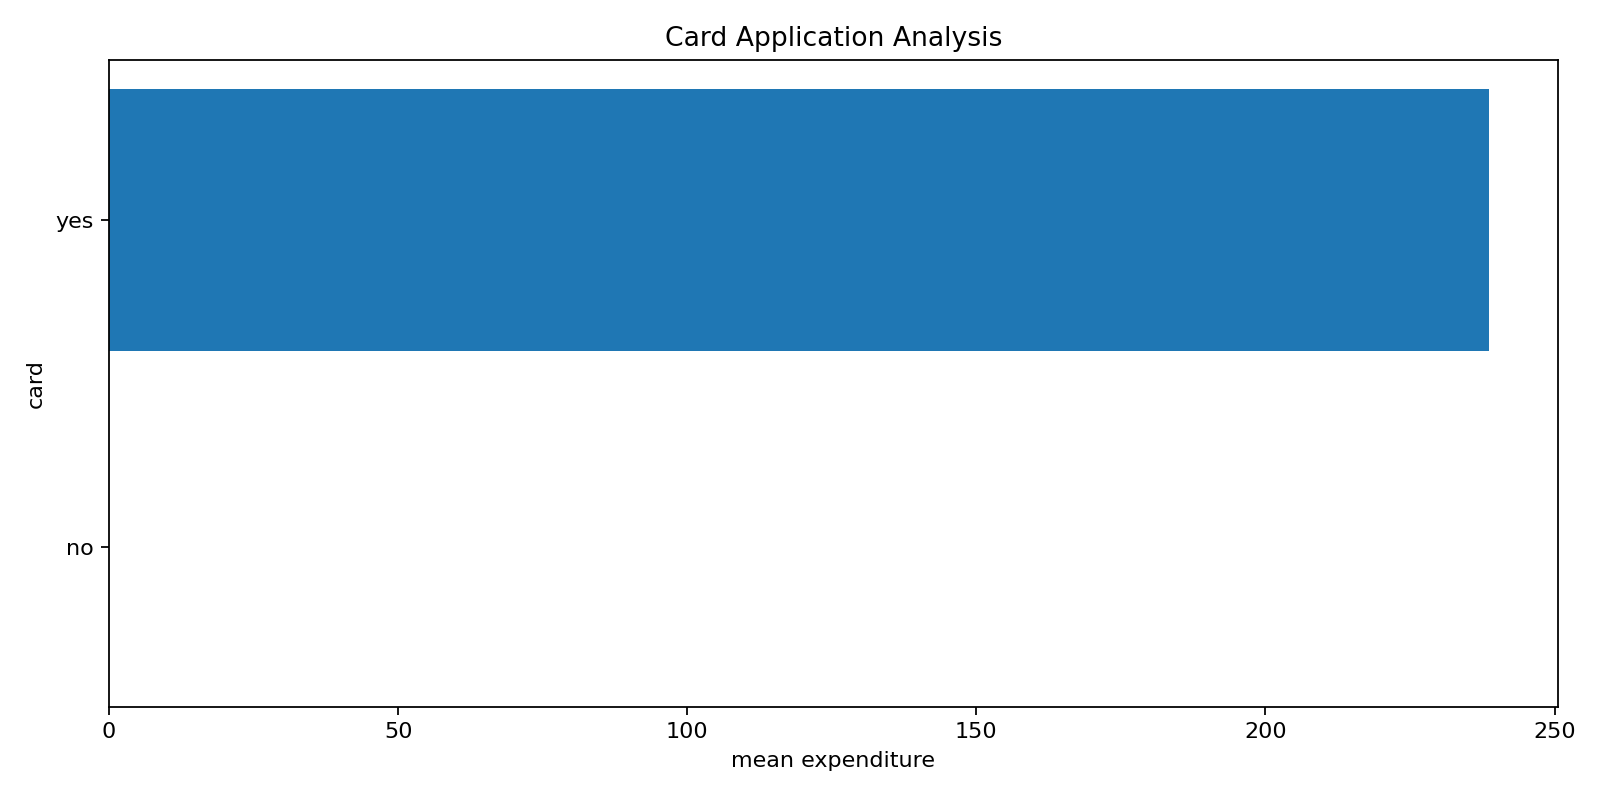

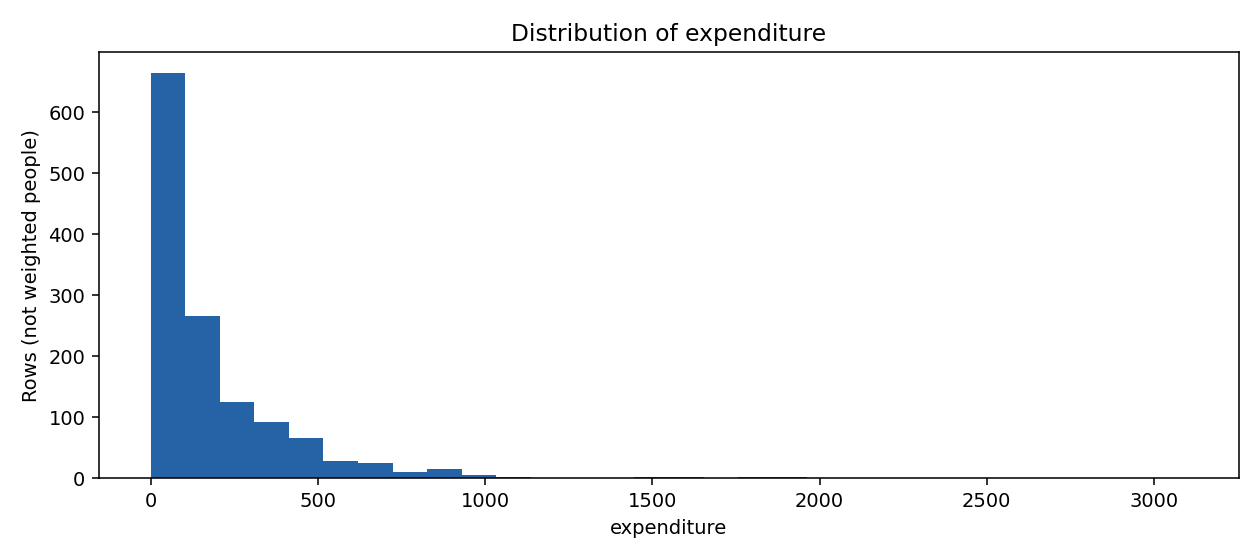

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Expenditure zeros and acceptance selection require source interpretation; this is not a validated lending model.

**Next action:** Audit zero expenditures and selection before customer segmentation.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.